# CA1 – Predicting Student Dropout and Academic Success
**Module:** Machine Learning  
**Student:** Yanjinkhorloo Munkhbold 
**Dataset:** Predict Students' Dropout and Academic Success (UCI Machine Learning Repository)  

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import warnings
warnings.filterwarnings('ignore')

## 2. Loading the Dataset

In [4]:
df=pd.read_csv('data/data.csv', sep=';')
df.rename(columns=({'Daytime/evening attendance\t': 'Daytime/evening attendance'}), inplace=True)
df.head

<bound method NDFrame.head of       Marital status  Application mode  Application order  Course  \
0                  1                17                  5     171   
1                  1                15                  1    9254   
2                  1                 1                  5    9070   
3                  1                17                  2    9773   
4                  2                39                  1    8014   
...              ...               ...                ...     ...   
4419               1                 1                  6    9773   
4420               1                 1                  2    9773   
4421               1                 1                  1    9500   
4422               1                 1                  1    9147   
4423               1                10                  1    9773   

      Daytime/evening attendance  Previous qualification  \
0                              1                       1   
1                    

In [5]:
print('Rows and columns:', df.shape)

Rows and columns: (4424, 37)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [7]:
print('Total missing values:', df.isnull().sum().sum())
print('Duplicated rows:', df.duplicated().sum())

Total missing values: 0
Duplicated rows: 0


In [8]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [9]:
print(df['Target'].value_counts())
print(df['Target'].value_counts()/len(df)*100)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: count, dtype: float64


**Observations:**
- The dataset has 4424 rows and 37 columns.
- Missing values:0; duplicated rows:0.
- The target has 3 classes: Graduate (49.9%), Dropout (32.1%), Enrolled (17.9%), so the classes are imbalanced. Because Enrolled is the smallest class, the models may struggle to predict it, so F1-score will be checked alongside accuracy and stratify will be used when splitting.

## 3. Exploraty Data Analysis (EDA)

In [10]:
target_mapping={'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
df['Target']=df['Target'].map(target_mapping)
print(df['Target'].value_counts())

Target
2    2209
0    1421
1     794
Name: count, dtype: int64


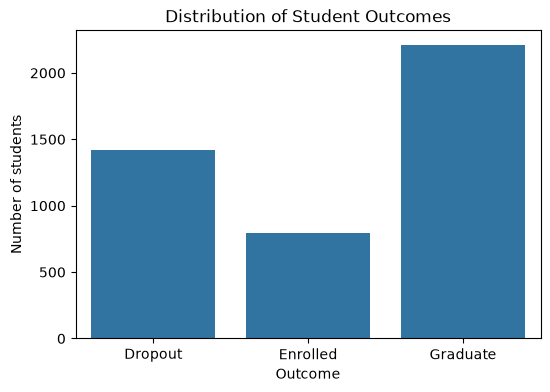

In [11]:
plt.figure(figsize = (6, 4))
sns.countplot(x = 'Target', data = df)
plt.title('Distribution of Student Outcomes')
plt.xticks([0, 1, 2], ['Dropout', 'Enrolled', 'Graduate'])
plt.xlabel('Outcome')
plt.ylabel('Number of students')
plt.show()

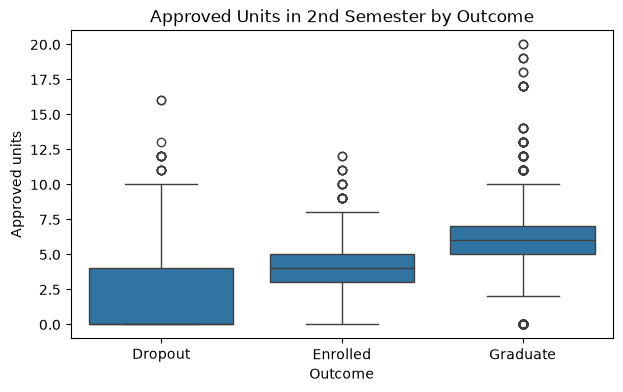

In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)')
plt.title('Approved Units in 2nd Semester by Outcome')
plt.xticks([0, 1, 2], ['Dropout', 'Enrolled', 'Graduate'])
plt.xlabel('Outcome')
plt.ylabel('Approved units')
plt.show()

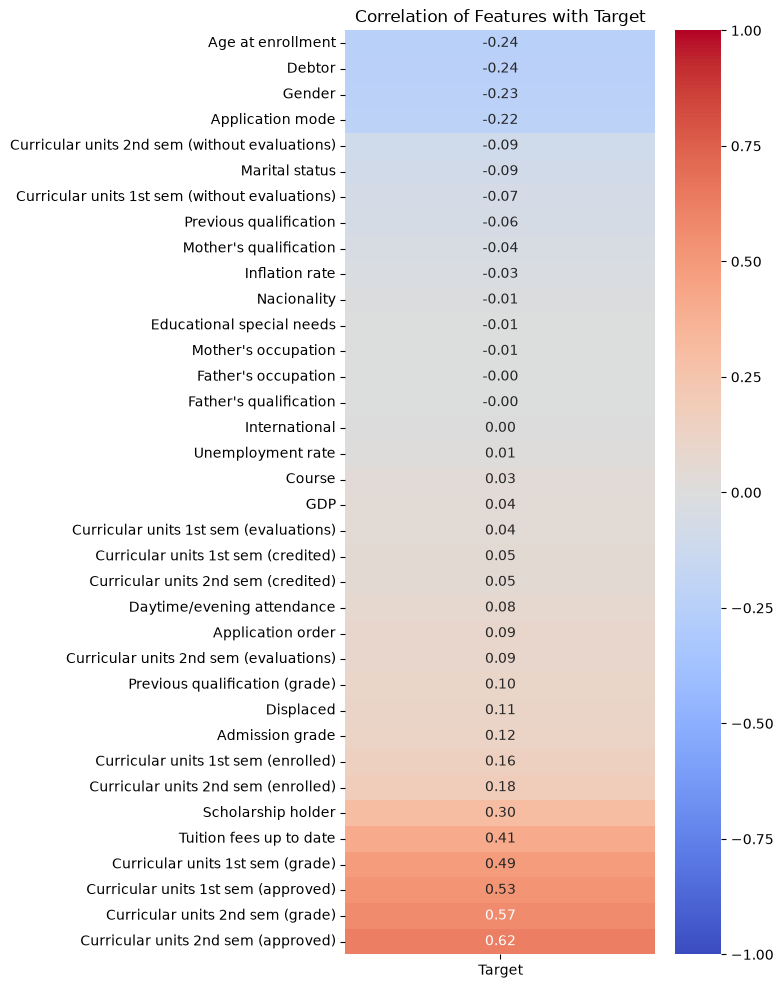

In [16]:
# Correlation of each feature with the Target, sorted from lowest to highest
corr_target=df.corr()[['Target']].sort_values(by='Target')
corr_target=df.corr()[['Target']].drop('Target').sort_values(by='Target')
plt.figure(figsize=(5, 12))
sns.heatmap(corr_target, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features with Target')
plt.show()

**EDA Observations:**
- Boxplot: Students who dropped out had fewer approved subjects in the 2nd semester compared to students who graduated.
- Academic performance: The number of approved subjects (r=0.62) and grades (r=0.57) in the 2nd semester have the strongest relationship with graduation. This means students who perform better academically are more likely to graduate.
- Financial factors: Students who pay their tuition fees on time (r=0.41) and receive scholarships (r=0.30) are more likely to garduate. Students with unoaid debts (r=-0.24) are more likely to drop out.
- Other factors: Nationality, parents, occupations, unemployment rate, and GDP have very little relationship with the final outcome
- Next step: Some categorical features, such as Course and Application mode, can not be properly understood using correlation. Therefore, we will use a Decision Tree to check their importance.

## 4. Data Pre-processing

In [17]:
X=df.drop(['Target'], axis=1).values
y=df['Target'].values
feature_names=df.drop(['Target'], axis=1).columns
X.shape, y.shape

((4424, 36), (4424,))